# Table of Contents
- [7.0 Introduction: three types of PDE](#intro)
- [7.1 The diffusion (heat) equation: FTCS](#ftcs)
- [7.2 Stability: von Neumann analysis](#stability)
- [7.3 Implicit methods: Crank-Nicolson](#cn)
- [7.4 The wave equation and the CFL condition](#wave)
- [7.5 The advection equation and upwinding](#advection)
- [7.6 Laplace's and Poisson's equations: relaxation](#laplace)
- [Problems](#problems)

# 7.0 Introduction: three types of PDE <a class="anchor" id="intro"></a>
Once more than one independent variable is involved (e.g. space *and* time) we have a **partial** differential equation. The three canonical second-order PDEs of physics are:

| Type | Prototype | Physics | Character |
| :--- | :--- | :--- | :--- |
| Parabolic | $\partial_t u = D\,\partial_x^2 u$ | heat flow, diffusion, Schrödinger | smooths things out |
| Hyperbolic | $\partial_t^2 u = c^2\,\partial_x^2 u$ | waves, sound, light | propagates information at finite speed |
| Elliptic | $\nabla^2 u = -\rho/\varepsilon_0$ | electrostatics, steady state, gravity | no time - a global equilibrium |

The type determines which numerical method is appropriate. Time-dependent problems are usually solved with the **method of lines**: discretise space with finite differences (Chapter 4) to get a big system of ODEs in time (Chapter 5), then step forward. Elliptic problems become big linear systems (Chapter 6).

In [1]:
# BLOCK 7.0.1
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

# 7.1 The diffusion (heat) equation: FTCS <a class="anchor" id="ftcs"></a>
Consider a metal rod of length $L$ whose ends are held at $0^\circ$C, with temperature $u(x,t)$ obeying

$$\frac{\partial u}{\partial t} = D\frac{\partial^2 u}{\partial x^2}.$$

Put $u$ on a grid $u_i^n \approx u(x_i, t_n)$ with spacings $\Delta x$, $\Delta t$. Using a **F**orward difference in **T**ime and a **C**entral difference in **S**pace (FTCS):

$$\frac{u_i^{n+1}-u_i^n}{\Delta t} = D\frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{\Delta x^2}
\quad\Longrightarrow\quad
u_i^{n+1} = u_i^n + r\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right),\qquad r = \frac{D\Delta t}{\Delta x^2}.$$

This is simply Euler's method applied to every grid point at once. With numpy slicing we can update the entire rod in one line - no loop over $i$.

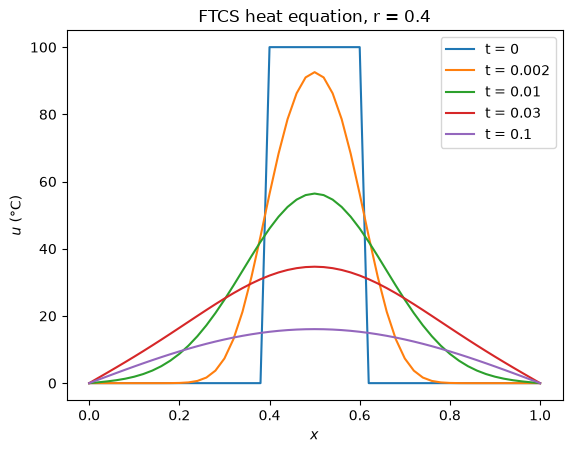

In [2]:
# BLOCK 7.1.1
def ftcs_heat(u0, r, n_steps):
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = u[1:-1] + r*(u[2:] - 2*u[1:-1] + u[:-2])   # ends stay fixed at their initial values
    return u

L, D, Nx = 1.0, 1.0, 51
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
# a hot spot in the middle; its edges (0.39 and 0.61) sit half-way between grid points
u0 = np.where(np.abs(x - 0.5) < 0.11, 100.0, 0.0)
u0[0] = u0[-1] = 0

r = 0.4
dt = r*dx**2/D
for t_show in [0, 0.002, 0.01, 0.03, 0.1]:
    n = int(round(t_show/dt))
    plt.plot(x, ftcs_heat(u0, r, n), label=f't = {t_show}')
plt.xlabel('$x$'); plt.ylabel('$u$ (°C)'); plt.legend(); plt.title(f'FTCS heat equation, r = {r}')
plt.show()

# 7.2 Stability: von Neumann analysis <a class="anchor" id="stability"></a>
Now try a slightly bigger time step, $r=0.52$:

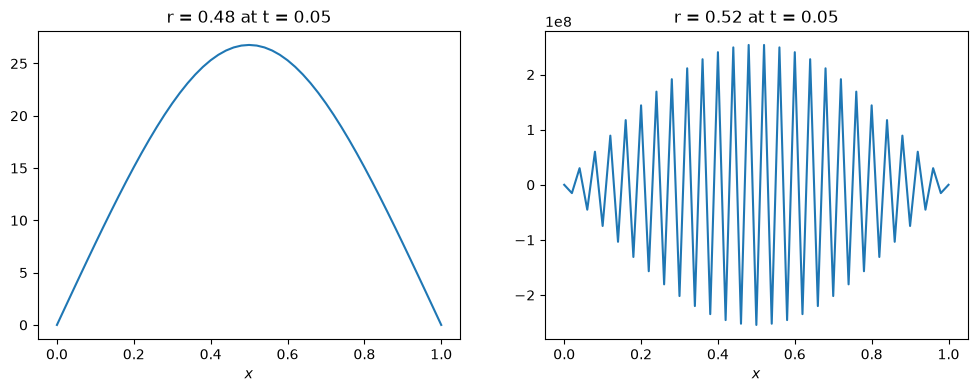

In [3]:
# BLOCK 7.2.1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, r in zip(axes, [0.48, 0.52]):
    dt = r*dx**2/D
    ax.plot(x, ftcs_heat(u0, r, int(0.05/dt)))
    ax.set_title(f'r = {r} at t = 0.05'); ax.set_xlabel('$x$')
plt.show()

Garbage! Tiny round-off errors at the grid scale have grown exponentially. To understand why, insert a single Fourier mode $u_i^n = G^n e^{ikx_i}$ into the FTCS update. The amplification factor per step is

$$G = 1 + r\left(e^{ik\Delta x} - 2 + e^{-ik\Delta x}\right) = 1 - 4r\sin^2\!\left(\frac{k\Delta x}{2}\right).$$

For stability we need $|G|\le 1$ for every $k$. The worst case is $\sin^2=1$, giving $|1-4r|\le1$, i.e.

$$\boxed{r = \frac{D\Delta t}{\Delta x^2}\le\frac{1}{2}}.$$

This is a harsh condition: halving $\Delta x$ forces you to quarter $\Delta t$, so a fine grid costs $8\times$ more. This is the PDE version of the stiffness we met in Chapter 5.

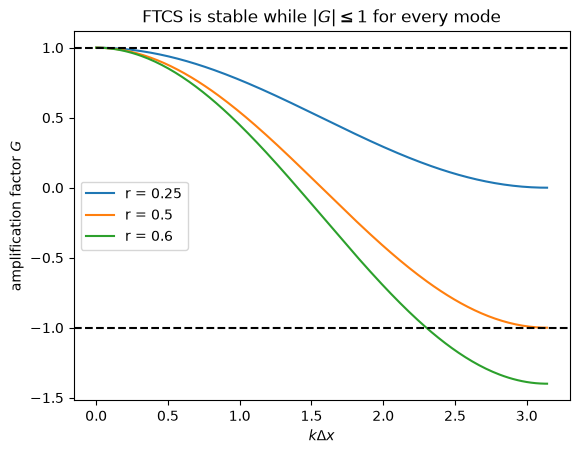

In [4]:
# BLOCK 7.2.2
kdx = np.linspace(0, np.pi, 200)
for r in [0.25, 0.5, 0.6]:
    plt.plot(kdx, 1 - 4*r*np.sin(kdx/2)**2, label=f'r = {r}')
plt.axhline(-1, color='k', ls='--'); plt.axhline(1, color='k', ls='--')
plt.xlabel(r'$k\Delta x$'); plt.ylabel('amplification factor $G$'); plt.legend()
plt.title('FTCS is stable while $|G| \\leq 1$ for every mode'); plt.show()

# 7.3 Implicit methods: Crank-Nicolson <a class="anchor" id="cn"></a>
Average the spatial derivative between the old and new time levels (the trapezium rule in time):

$$\frac{u_i^{n+1}-u_i^n}{\Delta t} = \frac{D}{2}\left[\frac{u_{i+1}^{n+1} - 2u_i^{n+1} + u_{i-1}^{n+1}}{\Delta x^2} + \frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{\Delta x^2}\right].$$

Collecting the unknown $n+1$ values on the left:

$$-\tfrac{r}{2}u_{i-1}^{n+1} + (1+r)u_i^{n+1} - \tfrac{r}{2}u_{i+1}^{n+1} = \tfrac{r}{2}u_{i-1}^{n} + (1-r)u_i^{n} + \tfrac{r}{2}u_{i+1}^{n}.$$

Every step requires solving a **tridiagonal** system - cheap, thanks to Chapter 6. In return Crank-Nicolson is **unconditionally stable** ($|G|\le1$ for all $r$) and second-order accurate in both space and time. We'll reuse it for the Schrödinger equation in the QM applications notebook.

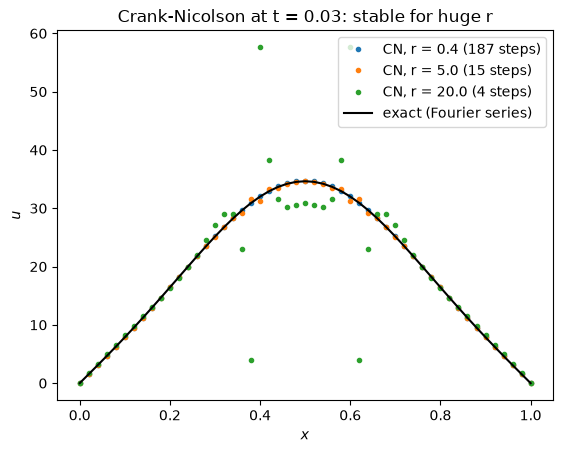

In [5]:
# BLOCK 7.3.1
def crank_nicolson_heat(u0, r, n_steps):
    """Heat equation with u = 0 at both ends. Uses scipy's banded solver for the tridiagonal system."""
    u = u0.copy()
    n = len(u) - 2                                  # interior points
    ab = np.zeros((3, n))                           # banded storage of the LHS matrix
    ab[0, 1:] = -r/2
    ab[1, :] = 1 + r
    ab[2, :-1] = -r/2
    for _ in range(n_steps):
        rhs = (r/2)*u[:-2] + (1 - r)*u[1:-1] + (r/2)*u[2:]
        u[1:-1] = linalg.solve_banded((1, 1), ab, rhs)
    return u

# Compare against the exact Fourier-series solution of the same problem
def exact_heat(x, t, n_terms=400):
    u = np.zeros_like(x)
    for m in range(1, n_terms + 1):
        bm = 2*100/(m*np.pi)*(np.cos(m*np.pi*0.39) - np.cos(m*np.pi*0.61))
        u += bm*np.sin(m*np.pi*x)*np.exp(-(m*np.pi)**2*D*t)
    return u

t_end = 0.03
for r in [0.4, 5.0, 20.0]:
    dt = r*dx**2/D
    n = int(round(t_end/dt))
    plt.plot(x, crank_nicolson_heat(u0, r, n), 'o', ms=3, label=f'CN, r = {r} ({n} steps)')
plt.plot(x, exact_heat(x, t_end), 'k', label='exact (Fourier series)')
plt.xlabel('$x$'); plt.ylabel('$u$'); plt.legend(); plt.title(f'Crank-Nicolson at t = {t_end}: stable for huge r')
plt.show()

With $r=5$ (ten times beyond the FTCS limit) Crank-Nicolson is still accurate using 12$\times$ fewer steps. At $r=20$ it remains *stable* - nothing blows up - but the sharp edges of the initial hot spot leave decaying wiggles: Crank-Nicolson barely damps high-frequency modes ($G\to-1$ as $r\to\infty$). Fully implicit backward Euler damps them hard, at the price of first-order accuracy in time. Stability is not the same thing as accuracy!

# 7.4 The wave equation and the CFL condition <a class="anchor" id="wave"></a>
For a plucked string, $\partial_t^2 u = c^2\partial_x^2 u$. Central differences in **both** time and space give the leapfrog scheme

$$u_i^{n+1} = 2u_i^n - u_i^{n-1} + C^2\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right), \qquad C = \frac{c\,\Delta t}{\Delta x}.$$

$C$ is the **Courant number**. A von Neumann analysis shows the scheme is stable only if $C\le1$: the **Courant-Friedrichs-Lewy (CFL) condition**. Physically, information on the grid can travel at most one cell per step, so the numerical speed $\Delta x/\Delta t$ must be at least the physical speed $c$. (At exactly $C=1$ this scheme is, remarkably, exact!)

To start we need $u^{-1}$; for a string released from rest ($\partial_t u=0$), a Taylor expansion gives $u_i^{1} = u_i^0 + \tfrac{C^2}{2}(u_{i+1}^0 - 2u_i^0 + u_{i-1}^0)$.

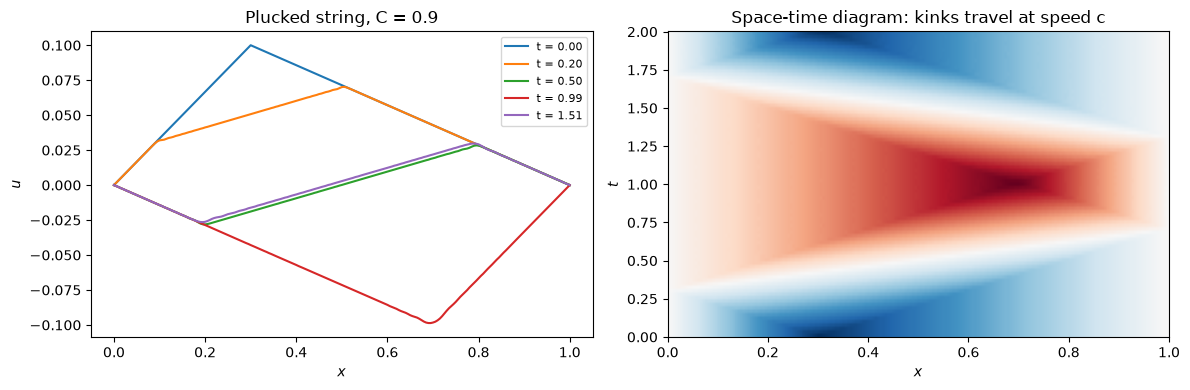

In [6]:
# BLOCK 7.4.1
def wave_leapfrog(u0, C, n_steps, store_every=1):
    u_prev = u0.copy()
    u = u0.copy()
    u[1:-1] = u0[1:-1] + 0.5*C**2*(u0[2:] - 2*u0[1:-1] + u0[:-2])
    frames = [u0.copy()]
    for n in range(1, n_steps):
        u_next = np.zeros_like(u)
        u_next[1:-1] = 2*u[1:-1] - u_prev[1:-1] + C**2*(u[2:] - 2*u[1:-1] + u[:-2])
        u_prev, u = u, u_next
        if n % store_every == 0:
            frames.append(u.copy())
    return np.array(frames)

Nx = 201
x = np.linspace(0, 1, Nx)
dx = x[1] - x[0]
pluck = np.where(x < 0.3, x/0.3, (1 - x)/0.7) * 0.1        # triangular pluck at x = 0.3
C = 0.9
c = 1.0
dt = C*dx/c
frames = wave_leapfrog(pluck, C, int(2.0/dt), store_every=5)   # one full period is 2L/c = 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for t_show in [0, 0.2, 0.5, 1.0, 1.5]:
    k = int(round(t_show/(5*dt)))               # frames are stored every 5 steps
    ax1.plot(x, frames[k], label=f't = {k*5*dt:.2f}')
ax1.set_xlabel('$x$'); ax1.set_ylabel('$u$'); ax1.legend(fontsize=8); ax1.set_title('Plucked string, C = 0.9')
ax2.imshow(frames, aspect='auto', origin='lower', extent=[0, 1, 0, frames.shape[0]*5*dt], cmap='RdBu')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$t$'); ax2.set_title('Space-time diagram: kinks travel at speed c')
plt.tight_layout(); plt.show()

# 7.5 The advection equation and upwinding <a class="anchor" id="advection"></a>
The simplest hyperbolic equation, $\partial_t u + v\,\partial_x u = 0$, just slides a profile along at speed $v$. It's a great test bed because the exact answer is trivial: $u(x,t)=u_0(x - vt)$. Yet it is surprisingly hard to solve well:

- **FTCS** (central difference in space) is *unconditionally unstable* - don't use it!
- **Upwind**: use a one-sided difference taking information from the direction the flow comes *from*: $u_i^{n+1} = u_i^n - C(u_i^n - u_{i-1}^n)$ for $v>0$. Stable for $C\le1$, but first order, and it smears out sharp features (*numerical diffusion*).
- **Lax-Wendroff**: second order, sharper, but creates spurious wiggles near discontinuities (*numerical dispersion*).

Modern codes for fluid dynamics and astrophysics use clever "flux limiters" to get the best of both.

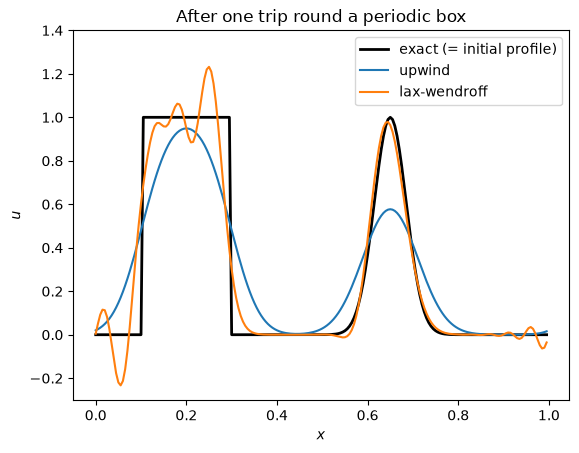

max |u| with FTCS after one trip: 1.0740857175344461e+18


In [7]:
# BLOCK 7.5.1
Nx = 200
x = np.linspace(0, 1, Nx, endpoint=False)           # periodic domain
dx = x[1] - x[0]
u0 = np.where((x > 0.1) & (x < 0.3), 1.0, 0.0) + np.exp(-((x - 0.65)/0.05)**2)
C = 0.5
n_steps = int(1.0/(C*dx))                            # one full trip round the box (v = 1)

def advect(u0, scheme):
    u = u0.copy()
    for _ in range(n_steps):
        up, um = np.roll(u, -1), np.roll(u, 1)        # u_{i+1}, u_{i-1} with periodic wrap
        if scheme == 'upwind':
            u = u - C*(u - um)
        elif scheme == 'lax-wendroff':
            u = u - 0.5*C*(up - um) + 0.5*C**2*(up - 2*u + um)
        elif scheme == 'ftcs':
            u = u - 0.5*C*(up - um)
    return u

plt.plot(x, u0, 'k', lw=2, label='exact (= initial profile)')
for s in ['upwind', 'lax-wendroff']:
    plt.plot(x, advect(u0, s), label=s)
plt.ylim(-0.3, 1.4); plt.xlabel('$x$'); plt.ylabel('$u$'); plt.legend()
plt.title('After one trip round a periodic box')
plt.show()
print('max |u| with FTCS after one trip:', np.abs(advect(u0, 'ftcs')).max())

# 7.6 Laplace's and Poisson's equations: relaxation <a class="anchor" id="laplace"></a>
In electrostatics, the potential in a charge-free region satisfies $\nabla^2\phi=0$. Discretise on a square grid with $\Delta x=\Delta y=h$:

$$\frac{\phi_{i+1,j}+\phi_{i-1,j}+\phi_{i,j+1}+\phi_{i,j-1}-4\phi_{i,j}}{h^2}=0
\quad\Longrightarrow\quad
\phi_{i,j} = \tfrac14\left(\phi_{i+1,j}+\phi_{i-1,j}+\phi_{i,j+1}+\phi_{i,j-1}\right).$$

The potential at each point is the **average of its neighbours**! This suggests **relaxation**: start with a guess and repeatedly replace every point with the average of its neighbours, keeping the boundary values fixed. This is exactly the Jacobi iteration from Chapter 6, and Gauss-Seidel / SOR speed it up in the same way.

A neat trick to vectorise Gauss-Seidel: colour the grid like a chessboard. Every red square's neighbours are black, so we can update **all red** points at once, then **all black** points (*red-black ordering*).

**Example:** a square box whose top lid is held at $V=1$ and other three sides are grounded.

Jacobi              :  2151 iterations


Gauss-Seidel        :  1245 iterations


SOR (ω = 1.882)     :    90 iterations


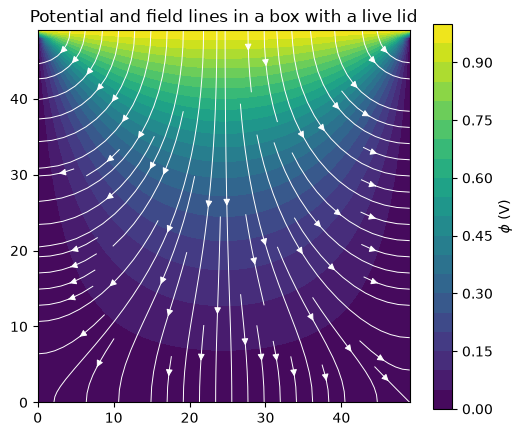

In [8]:
# BLOCK 7.6.1
def laplace_relax(phi, fixed, method='jacobi', omega=1.0, tol=1e-5, max_iter=50000):
    """Relax phi until converged. `fixed` is a boolean mask of points that must not change."""
    phi = phi.copy()
    ny, nx = phi.shape
    I, J = np.meshgrid(np.arange(ny), np.arange(nx), indexing='ij')
    colours = [((I + J) % 2 == 0) & ~fixed, ((I + J) % 2 == 1) & ~fixed]
    for it in range(max_iter):
        old = phi.copy()
        if method == 'jacobi':
            avg = np.zeros_like(phi)
            avg[1:-1, 1:-1] = 0.25*(phi[2:, 1:-1] + phi[:-2, 1:-1] + phi[1:-1, 2:] + phi[1:-1, :-2])
            phi[~fixed] = avg[~fixed]
        else:                                    # red-black SOR (omega = 1 -> Gauss-Seidel)
            for mask in colours:
                avg = np.zeros_like(phi)
                avg[1:-1, 1:-1] = 0.25*(phi[2:, 1:-1] + phi[:-2, 1:-1] + phi[1:-1, 2:] + phi[1:-1, :-2])
                phi[mask] = (1 - omega)*phi[mask] + omega*avg[mask]
        if np.max(np.abs(phi - old)) < tol:
            break
    return phi, it + 1

N = 50
phi0 = np.zeros((N, N))
phi0[-1, :] = 1.0                                # top lid at V = 1
fixed = np.zeros((N, N), bool)
fixed[0, :] = fixed[-1, :] = fixed[:, 0] = fixed[:, -1] = True

omega_opt = 2/(1 + np.sin(np.pi/N))
results = {}
for name, kw in {'Jacobi': dict(method='jacobi'),
                 'Gauss-Seidel': dict(method='sor', omega=1.0),
                 f'SOR (ω = {omega_opt:.3f})': dict(method='sor', omega=omega_opt)}.items():
    results[name] = laplace_relax(phi0, fixed, **kw)
    print(f'{name:<20}: {results[name][1]:>5} iterations')

phi = results[f'SOR (ω = {omega_opt:.3f})'][0]
Ey, Ex = np.gradient(-phi)
fig, ax = plt.subplots(figsize=(6, 5))
cs = ax.contourf(phi, levels=20, cmap='viridis'); fig.colorbar(cs, label=r'$\phi$ (V)')
ax.streamplot(np.arange(N), np.arange(N), Ex, Ey, color='white', density=0.8, linewidth=0.7)
ax.set_title('Potential and field lines in a box with a live lid'); ax.set_aspect('equal')
plt.show()

For bigger problems, use sparse direct solvers (`scipy.sparse.linalg.spsolve`) or, for the really large ones, multigrid and conjugate-gradient methods.

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - Cooling with a heat sink
Modify the heat equation solver so that the right end of the rod is **insulated** ($\partial u/\partial x=0$, a *Neumann* condition). Hint: introduce a "ghost point" $u_{N+1}=u_{N-1}$. How does the temperature profile at late times differ?

### Exercise 2 - Breaking the CFL condition
Run `wave_leapfrog` with $C=1.0$ and $C=1.02$. Describe what happens. Then verify that with $C=1$ the triangular pluck returns *exactly* to its initial shape after one period.

### Exercise 3 - The 2D heat equation
Write an FTCS solver for $\partial_t u = D\nabla^2u$ on a 2D plate and animate (or plot snapshots of) a hot square cooling. What is the stability condition in 2D? (Hint: repeat the von Neumann analysis - you should find $r\le1/4$.)

### Exercise 4 - Parallel-plate capacitor
Using `laplace_relax`, solve for the potential of two finite plates at $\pm1$ V inside a large grounded box. Plot the equipotentials and field lines, and estimate the capacitance per unit length from the charge on one plate (Gauss's law: integrate $\mathbf{E}\cdot\hat{\mathbf{n}}$ round a loop enclosing it).

In [9]:
# Start working here

---
<details>
<summary>🥚</summary>

This is a deliberate easter egg, not part of the course, and nothing in it is examinable. Run the cell below.
</details>

In [10]:
# Easter egg (deliberate, not part of the course): an FTCS heat equation whose initial condition is a word.
rows = ["#   #  ###  ##### ",
        "#   # #   #   #   ",
        "##### #   #   #   ",
        "#   # #   #   #   ",
        "#   #  ###    #   "]
pad = 2
W, H = len(rows[0]) + 2*pad, len(rows) + 2*pad
u = [[0.0]*W for _ in range(H)]
for i, row in enumerate(rows):
    for j, ch in enumerate(row):
        if ch == "#":
            u[i + pad][j + pad] = 1.0       # hot pixels spell the word

shades = " .:-=+*#%@"
def show(u, label):
    print(label)
    for row in u:
        print("".join(shades[min(int(val*len(shades)), len(shades) - 1)] for val in row))

show(u, "t = 0")
r = 0.2                                     # 2D FTCS is stable for r <= 1/4
for step in range(1, 61):
    new = [row[:] for row in u]             # the edges stay at zero temperature
    for i in range(1, H - 1):
        for j in range(1, W - 1):
            new[i][j] = u[i][j] + r*(u[i+1][j] + u[i-1][j] + u[i][j+1] + u[i][j-1] - 4*u[i][j])
    u = new
    if step in (2, 60):
        peak = max(max(row) for row in u)
        show([[val/peak for val in row] for row in u], f"t = {step} steps (rescaled; peak temperature {peak:.2f})")
print("Everything diffuses. Even this joke.")

t = 0
                      
                      
  @   @  @@@  @@@@@   
  @   @ @   @   @     
  @@@@@ @   @   @     
  @   @ @   @   @     
  @   @  @@@    @     
                      
                      
t = 2 steps (rescaled; peak temperature 0.60)
                      
 ... ...::-::.:-=-:.  
 :+-:-+==*+*=-+#@#+.  
 -#*+*%*#+++*--*@*-.  
 =@@#@@%*+:++-:=#=.   
 -#*+*%*#+++*:.-*-    
 :+-:-+==*+*-: :+:    
 ... ...::-::  ...    
                      
t = 60 steps (rescaled; peak temperature 0.06)
                      
  .::----------:::..  
 .:-=+***##***++=-:.  
 .-=*#%%@@@%%%#*+=-:. 
 .-+*#%@@@@@@%%#*+=:. 
 .-=*#%%@@@%%%#*+=-:. 
 .:-=+***##***++=-:.  
  .::----------:::..  
                      
Everything diffuses. Even this joke.
